Social Network Lab

Conor Murray

In [21]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
dfNode = pd.read_csv('marvel_characters_combined.csv')
dfEdge = pd.read_csv('ID_co-occurrence.csv')
print(dfNode.head())
print(dfEdge.head())
print(dfNode.shape, dfEdge.shape)

        ID        Label Universe
0  1009504  Professor X    x-men
1  1009257      Cyclops    x-men
2  1009362       Iceman    x-men
3  1009159    Archangel    x-men
4  1009175        Beast    x-men
   Character1  Character2
0     1009159     1009163
1     1009159     1009163
2     1009159     1009168
3     1009159     1009168
4     1009159     1009168
(57, 3) (6180, 2)


In [22]:
dfEdge = dfEdge.groupby(['Character1', 'Character2']).size()
dfEdge = dfEdge.reset_index(name='duplication count')
dfEdge = dfEdge.rename(columns={'Character1': 'from', 'Character2': 'to', 'duplication count': 'weight'})
print(dfEdge.head())
print(dfEdge.shape)

      from       to  weight
0  1009159  1009163       2
1  1009159  1009168      12
2  1009159  1009175      26
3  1009159  1009182      14
4  1009159  1009219       6
(834, 3)


In [23]:
dfNode['color'] = 'red'
mask = dfNode['Universe'] == 'x-men'
dfNode.loc[mask, 'color'] = 'blue'
print(dfNode.head())
print(dfNode['color'].value_counts())

        ID        Label Universe color
0  1009504  Professor X    x-men  blue
1  1009257      Cyclops    x-men  blue
2  1009362       Iceman    x-men  blue
3  1009159    Archangel    x-men  blue
4  1009175        Beast    x-men  blue
color
blue    30
red     27
Name: count, dtype: int64


In [24]:
nameLookup = {}
universeLookup = {}
for i in range(len(dfNode)):
    charID = dfNode.loc[i, 'ID']
    nameLookup[charID] = dfNode.loc[i, 'Label']
    universeLookup[charID] = dfNode.loc[i, 'Universe']
dfEdge['fromUniverse'] = dfEdge['from'].map(universeLookup)
dfEdge['toUniverse'] = dfEdge['to'].map(universeLookup)
dfEdge['from'] = dfEdge['from'].map(nameLookup)
dfEdge['to'] = dfEdge['to'].map(nameLookup)
print(dfEdge.head())

        from          to  weight fromUniverse toUniverse
0  Archangel      Aurora       2        x-men      x-men
1  Archangel     Banshee      12        x-men      x-men
2  Archangel       Beast      26        x-men      x-men
3  Archangel      Bishop      14        x-men      x-men
4  Archangel  Cannonball       6        x-men      x-men


In [25]:
mask = dfEdge['fromUniverse'] != dfEdge['toUniverse']
dfEdge = dfEdge[mask]
print(dfEdge.head())
print(dfEdge.shape)

         from               to  weight fromUniverse toUniverse
5   Archangel  Captain America       4        x-men   avengers
12  Archangel         Galactus       2        x-men   avengers
16  Archangel         Hercules       2        x-men   avengers
17  Archangel             Hulk       4        x-men   avengers
19  Archangel         Iron Man       2        x-men   avengers
(286, 5)


In [26]:
G = nx.from_pandas_edgelist(dfEdge, source='from', target='to', edge_attr=True, create_using=nx.DiGraph())
print(G.number_of_nodes(), G.number_of_edges())

53 286


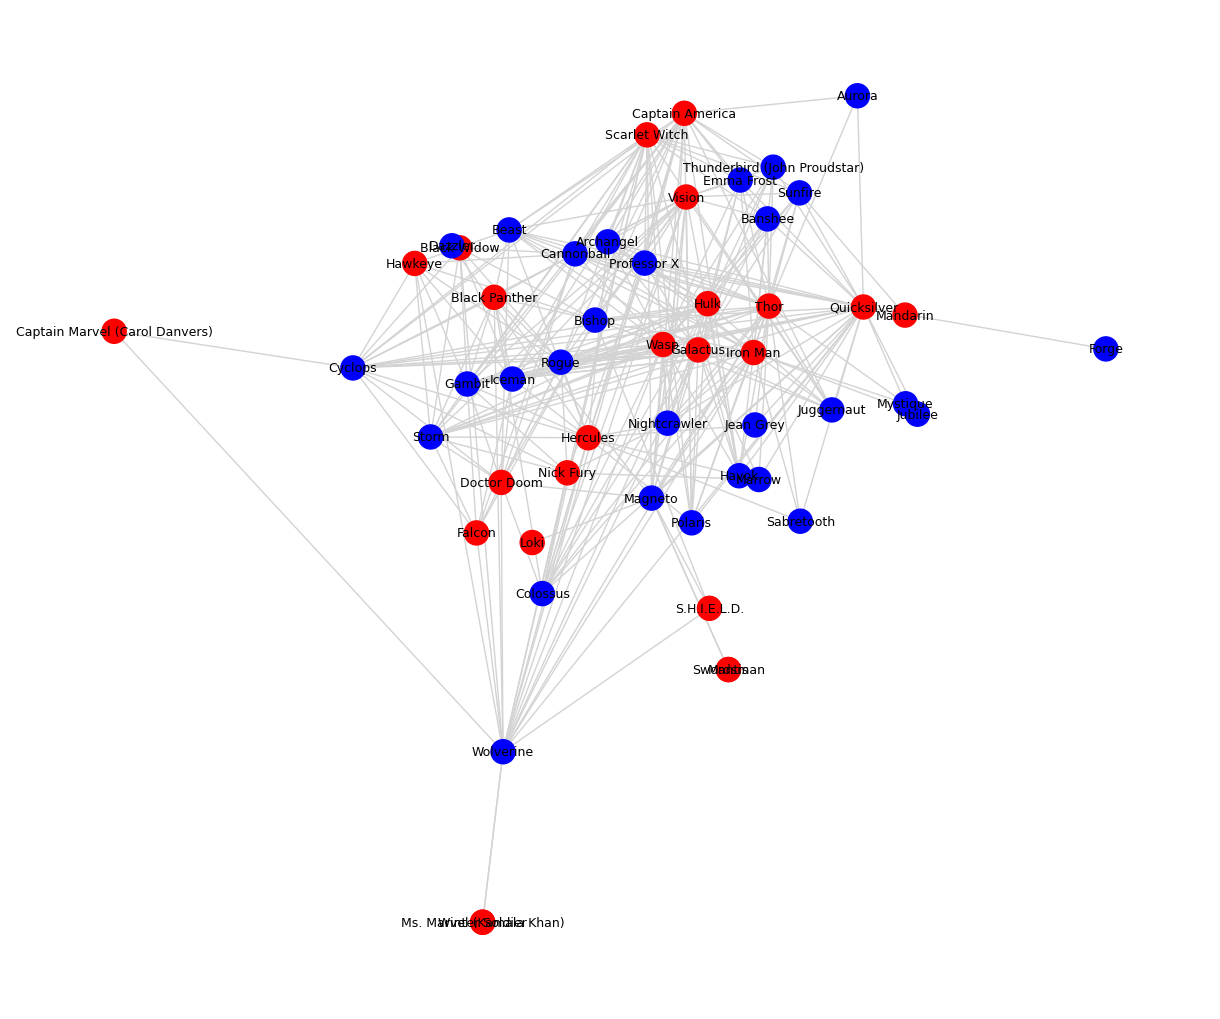

In [27]:
nodeColors = []
for node in G.nodes():
    mask = dfNode['Label'] == node
    nodeColors.append(dfNode.loc[mask, 'color'].values[0])
plt.figure(figsize=(12, 10))
pos = nx.kamada_kawai_layout(G)
nx.draw(G, pos, node_color=nodeColors, with_labels=True, edge_color='lightgray', font_size=9, arrows=False)
plt.show()

In [28]:
density = nx.density(G)
print('Network density:', round(density, 4))

Network density: 0.1038


In [29]:
degree = nx.degree_centrality(G)
dfDegree = pd.DataFrame(list(degree.items()), columns=['character', 'degree_centrality'])
dfDegree = dfDegree.sort_values('degree_centrality', ascending=False)
print(dfDegree.head(5))

         character  degree_centrality
6      Quicksilver           0.538462
8             Thor           0.500000
5         Iron Man           0.461538
1  Captain America           0.423077
4             Hulk           0.403846


In [30]:
closeness = nx.closeness_centrality(G)
dfCloseness = pd.DataFrame(list(closeness.items()), columns=['character', 'closeness_centrality'])
dfCloseness = dfCloseness.sort_values('closeness_centrality', ascending=False)
print(dfCloseness.head(5))

      character  closeness_centrality
8          Thor              0.538462
29    Wolverine              0.537731
9        Vision              0.489879
6   Quicksilver              0.480769
10         Wasp              0.477318


In [36]:
print(nx.has_path(G, 'Winter Soldier', 'Magneto'))
print('Since there is not a path from winter soldier to magneto in this directed network, I ran the shortest path backwards from magneto to winter soldier to find the length')
print(nx.shortest_path(G, 'Magneto', 'Winter Soldier'))
print('the shortest path is: ', (nx.shortest_path_length(G, 'Magneto', 'Winter Soldier')))

False
Since there is not a path from winter soldier to magneto in this directed network, I ran the shortest path backwards from magneto to winter soldier to find the length
['Magneto', 'Quicksilver', 'Wolverine', 'Winter Soldier']
the shortest path is:  3
